<a href="https://colab.research.google.com/github/enzopuc2007/RAM_Memory_Management/blob/main/src/Data_Work_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 2 — Sprint 1 — Planilha 1 (antes da intervenção)

Análise do uso da capacidade de memória RAM (%) em 300 servidores: representação gráfica, média e desvio-padrão, testes de normalidade, probabilidade em um intervalo e valores que limitam os 20% menores e os 30% maiores (Questões 2 a 6).

### Leitura dos dados

A planilha deve estar na mesma pasta do notebook.

In [1]:
# Importação das bibliotecas que são usadas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
import pylab

In [2]:
arquivo = 'Planilha 1 - Memória RAM.xlsx'
coluna = 'Memória_RAM_pct'

df = pd.read_excel(arquivo)
print(f"Observações lidas: {len(df)}")
df.head()

Observações lidas: 300


,Memória_RAM_pct
0,48.396517
1,47.650246
2,55.132804
3,38.561461
4,29.563274


### Questão 2 — Representação gráfica

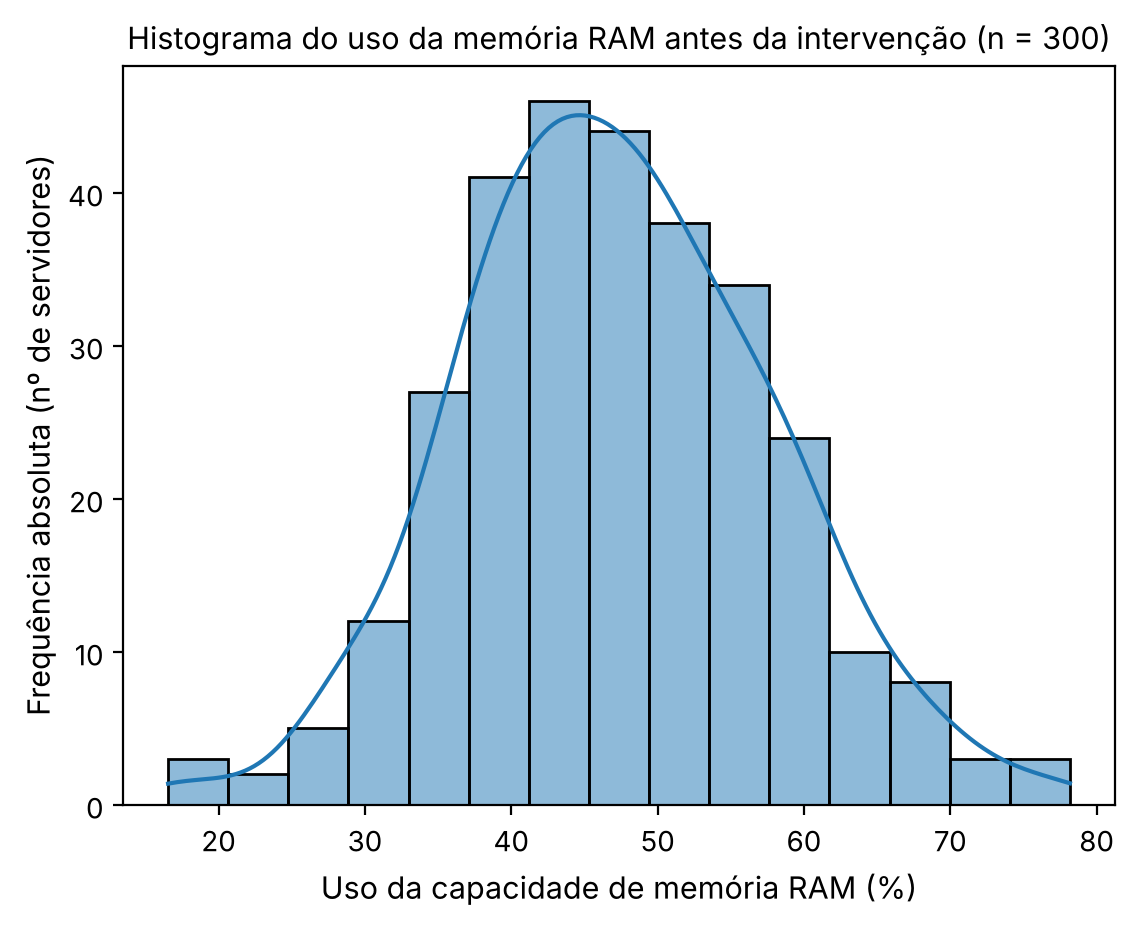

In [3]:
sns.histplot(data=df[coluna], kde=True)
plt.title('Histograma do uso da memória RAM antes da intervenção (n = 300)', fontsize=11)
plt.xlabel('Uso da capacidade de memória RAM (%)', fontsize=11)
plt.ylabel('Frequência absoluta (nº de servidores)', fontsize=11)
plt.show()

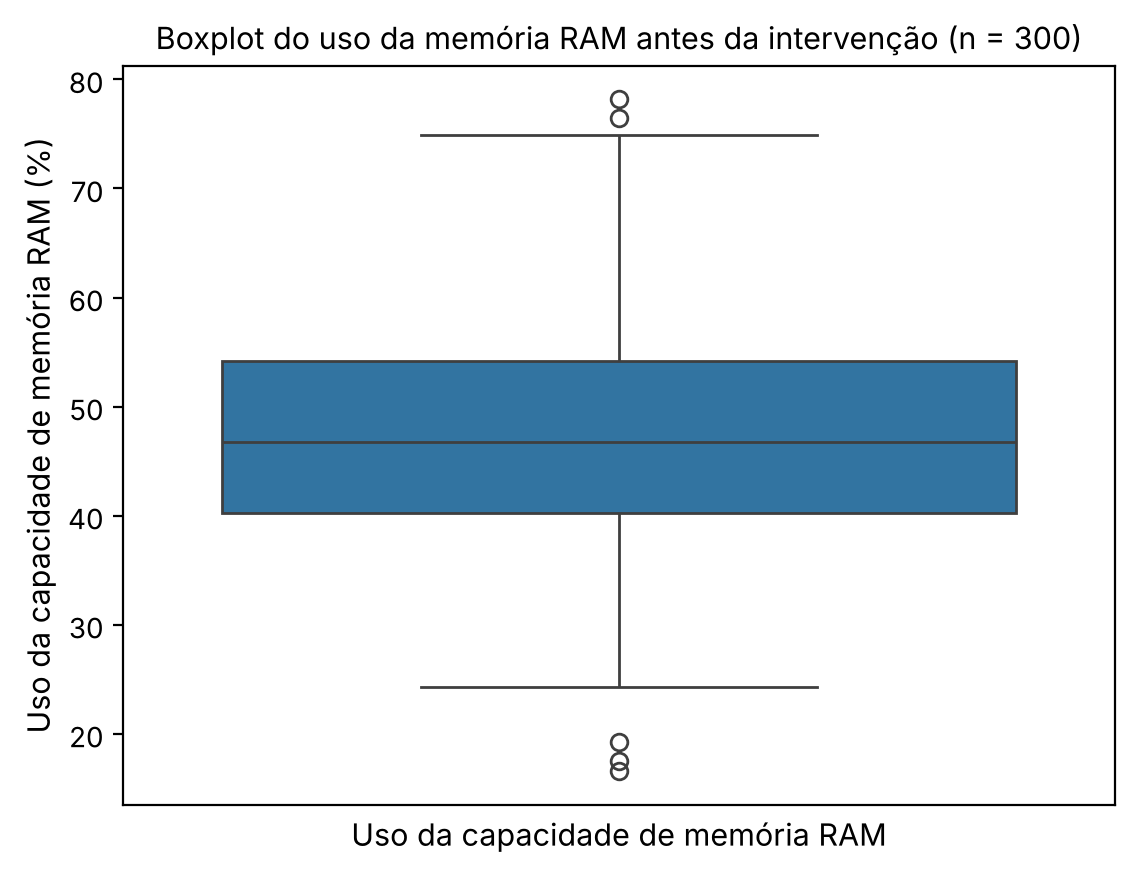

In [4]:
sns.boxplot(data=df[coluna])
plt.title('Boxplot do uso da memória RAM antes da intervenção (n = 300)', fontsize=11)
plt.ylabel('Uso da capacidade de memória RAM (%)', fontsize=11)
plt.xlabel('Uso da capacidade de memória RAM', fontsize=11)
plt.xticks([])
plt.show()

### Questão 3 — Média e desvio-padrão

Os dados constituem uma amostra, portanto usa-se o desvio-padrão amostral (`ddof=1`, padrão do pandas).

In [5]:
media = df[coluna].mean()
dpad = df[coluna].std(ddof=1)

print(f"Média .........: {media:.2f} %")
print(f"Desvio-padrão .: {dpad:.2f} pontos percentuais")

Média .........: 47.13 %
Desvio-padrão .: 10.52 pontos percentuais


### Questão 4 — Testes de normalidade

**a) Histograma:** único pico próximo da média e da mediana e comparação das proporções com a regra empírica 68%-95%-99,7%.

In [6]:
mediana = df[coluna].median()

print(f"Média ..........: {media:.2f} %")
print(f"Mediana ........: {mediana:.2f} %")
print(f"Diferença ......: {abs(media - mediana):.2f} ponto percentual")

Média ..........: 47.13 %
Mediana ........: 46.74 %
Diferença ......: 0.39 ponto percentual


In [7]:
regra_empirica = {1: 68, 2: 95, 3: 99.7}

for k, esperado in regra_empirica.items():
    limite_inf = round(media - k * dpad, 2)
    limite_sup = round(media + k * dpad, 2)
    quantidade = ((df[coluna] >= limite_inf) & (df[coluna] <= limite_sup)).sum()
    porcentagem = round(quantidade / len(df[coluna]) * 100, 2)
    print(f"Média ± {k} desvio(s)-padrão: [{limite_inf} ; {limite_sup}] -> "
          f"{quantidade} observações = {porcentagem} % (regra empírica: {esperado} %)")

Média ± 1 desvio(s)-padrão: [36.6 ; 57.65] -> 206 observações = 68.67 % (regra empírica: 68 %)
Média ± 2 desvio(s)-padrão: [26.08 ; 68.17] -> 287 observações = 95.67 % (regra empírica: 95 %)
Média ± 3 desvio(s)-padrão: [15.56 ; 78.7] -> 300 observações = 100.0 % (regra empírica: 99.7 %)


**b) Simetria do boxplot:** comparação das distâncias entre os quartis.

In [8]:
Q1 = df[coluna].quantile(q=0.25)
Q2 = df[coluna].quantile(q=0.50)
Q3 = df[coluna].quantile(q=0.75)

print(f"Q1 ...........: {Q1:.2f} %")
print(f"Q2 (mediana) .: {Q2:.2f} %")
print(f"Q3 ...........: {Q3:.2f} %")
print(f"Q2 - Q1 ......: {Q2 - Q1:.2f} pontos percentuais")
print(f"Q3 - Q2 ......: {Q3 - Q2:.2f} pontos percentuais")

Q1 ...........: 40.28 %
Q2 (mediana) .: 46.74 %
Q3 ...........: 54.20 %
Q2 - Q1 ......: 6.46 pontos percentuais
Q3 - Q2 ......: 7.46 pontos percentuais


In [9]:
AIQ = Q3 - Q1
limite_inferior = Q1 - 1.5 * AIQ
limite_superior = Q3 + 1.5 * AIQ
discrepantes = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

print(f"AIQ ..............: {AIQ:.2f} pontos percentuais")
print(f"Limite inferior ..: {limite_inferior:.2f} %")
print(f"Limite superior ..: {limite_superior:.2f} %")
print(f"Valores discrepantes: {len(discrepantes)} "
      f"({len(discrepantes) / len(df) * 100:.2f} % das observações)")

AIQ ..............: 13.92 pontos percentuais
Limite inferior ..: 19.40 %
Limite superior ..: 75.09 %
Valores discrepantes: 5 (1.67 % das observações)


**c) Diagrama Q-Q.**

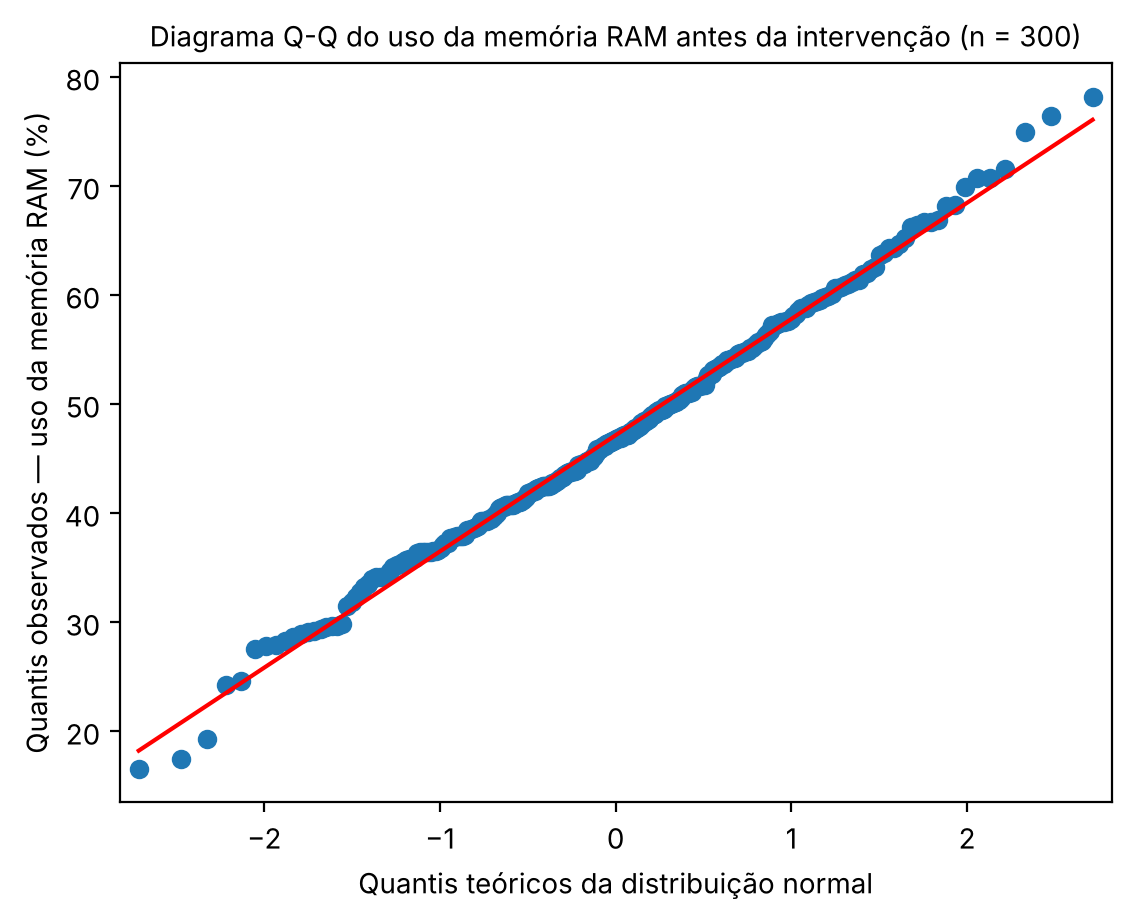

In [10]:
sm.qqplot(df[coluna], line='r')
plt.title('Diagrama Q-Q do uso da memória RAM antes da intervenção (n = 300)', fontsize=10)
plt.xlabel('Quantis teóricos da distribuição normal', fontsize=10)
plt.ylabel('Quantis observados — uso da memória RAM (%)', fontsize=10)
pylab.show()

### Questão 5 — Probabilidade no intervalo [a, b]

Os limites são os valores de referência da Questão 1: faixa de uso considerada adequada, de 40% a 60% da capacidade. Como os testes da Questão 4 indicaram compatibilidade com a distribuição normal, usa-se a normal com a média e o desvio-padrão da Questão 3.

In [11]:
a = 40
b = 60

probabilidade = norm.cdf(b, media, dpad) - norm.cdf(a, media, dpad)
print(f"P({a} <= X <= {b}) = {probabilidade:.4f}  ->  {probabilidade * 100:.2f} %")

P(40 <= X <= 60) = 0.6403  ->  64.03 %


In [12]:
# conferência com a proporção observada na planilha
dentro = ((df[coluna] >= a) & (df[coluna] <= b)).sum()
print(f"Observações entre {a} % e {b} %: {dentro} de {len(df)} = {dentro / len(df) * 100:.2f} %")

Observações entre 40 % e 60 %: 192 de 300 = 64.00 %


### Questão 6 — Valores que limitam os 20% menores e os 30% maiores

In [13]:
menor = norm.ppf(0.20, loc=media, scale=dpad)
maior = norm.ppf(0.70, loc=media, scale=dpad)

print(f"Valor máximo para estar entre os 20% menores: {menor:.2f} %")
print(f"Valor mínimo para estar entre os 30% maiores: {maior:.2f} %")

Valor máximo para estar entre os 20% menores: 38.27 %
Valor mínimo para estar entre os 30% maiores: 52.65 %
